# Default and tuned classifier comparison

CM2604 Coursework 1, Part 01. This notebook compares validation results and reports a configuration frozen before any held-out test evaluation. It reads explicit saved search results and independently re-evaluates the six frozen configurations. Run `python -m src.train --tune` first to reproduce the full search.

## How the models work

| Model | Prediction method | Starting configuration |
|---|---|---|
| KNN | Finds the five nearest training customers in the transformed feature space and uses their labels to vote. Churn probability is the fraction of those neighbours labelled Yes. | 5 neighbours, uniform weights, Euclidean distance; scaled numeric predictors |
| Logistic regression | Learns a weighted sum of the predictors and converts it to a churn probability using the sigmoid function, p = 1 / (1 + exp(-z)). Regularisation limits coefficient size. | C=1, lbfgs solver, max_iter=2000, no class weights; scaled numeric predictors |
| Random forest | Fits 100 trees on bootstrap samples, considering random feature subsets at splits, then averages their class probabilities. | 100 trees, unrestricted depth, seed 42; unscaled numeric predictors |

These descriptions follow scikit-learn developers (n.d.a, n.d.b, n.d.c). KNN depends on the distance representation; logistic regression uses a linear score before the sigmoid; unrestricted trees can learn detailed training patterns. These properties motivate the bounded tuning below.

## Fixed search and evaluation method

The three grids were fixed before tuning: KNN uses neighbours 5, 11, 21, 31; uniform/distance weights; p=1 or 2. Logistic regression uses C=0.01, 0.1, 1, 10 and class weighting None/balanced. Random forest uses 100/200 trees, depth None/10, minimum leaf size 1/5 and class weighting None/balanced. This gives 16, 8 and 16 combinations, or 200 validation fits across five folds, plus three training-only refits of the winning searches.

GridSearchCV fits the entire preprocessing/model pipeline separately inside each fold. It selects parameters by mean churn F1 and records all seven metrics (scikit-learn developers, n.d.d). Five stratified folds shuffle with seed 42, using only the fixed 5,634-row training partition. The positive class is Yes=1. The normal 0.5 decision boundary stays fixed; exact probability ties favour No. Numeric imputation/scaling and categorical modes/encoding learn only from each fitting subset.

The final choice compares all six default/tuned configurations by training CV F1. Exact model ties prefer logistic regression, then KNN, then random forest. Within one model an exact default/tuned tie prefers default; within a search the first tied ParameterGrid candidate wins. No held-out test score enters selection. Search scores helped select the parameters and may be optimistic; these are not independent estimates of final performance.

In [1]:
from pathlib import Path
import sys, json, hashlib, warnings
ROOT = Path.cwd().resolve()
if not (ROOT / "src" / "data.py").is_file(): ROOT = ROOT.parent
if not (ROOT / "src" / "data.py").is_file(): raise RuntimeError("Run from the repository root or notebooks folder")
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import Image, Markdown, display
from sklearn.exceptions import ConvergenceWarning
from sklearn.model_selection import ParameterGrid
from src.data import load_data, split_data, CSV_SHA256, NUMERIC_COLUMNS, CATEGORIES
from src.models import build_default_models, fixed_search_grids
from src.train import SCORING, fixed_folds, evaluate_pipeline, summarise_cv, choose_configuration
TABLES = ROOT / "outputs" / "tables"
frozen = json.loads((ROOT / "outputs" / "frozen_configuration.json").read_text())
metadata = json.loads((TABLES / "tuning_configuration.json").read_text())
comparison = pd.read_csv(TABLES / "default_tuned_comparison.csv")
X_train, X_test, y_train, y_test = split_data(load_data())
held_out_indices = set(X_test.index)
assert not set(X_train.index) & held_out_indices
assert len(X_train) == frozen["training_rows"] == 5634
assert frozen["csv_sha256"] == CSV_SHA256
index_hash = hashlib.sha256(json.dumps(list(map(int, X_train.index))).encode()).hexdigest()
assert frozen["training_index_sha256"] == index_hash
del X_test, y_test

## Search results and chosen parameters

Every candidate's five fold scores, means, standard deviations, ranks and timing summaries are retained in its search CSV. The checks below recompute score summaries and verify that the selected parameter dictionary belongs to the approved grid and attains the maximum mean F1.

In [2]:
parameter_rows = []
for name, grid in fixed_search_grids().items():
    table = pd.read_csv(TABLES / f"{name}_search_results.csv")
    assert len(table) == len(ParameterGrid(grid)) == metadata[name]["candidates"]
    actual_parameters = [json.loads(text) for text in table.parameters_json]
    assert actual_parameters == list(ParameterGrid(grid))
    for metric in SCORING:
        scores = table[[f"split{i}_test_{metric}" for i in range(5)]].to_numpy()
        assert np.isfinite(scores).all()
        np.testing.assert_allclose(table[f"mean_test_{metric}"], scores.mean(axis=1))
        np.testing.assert_allclose(table[f"std_test_{metric}"], scores.std(axis=1, ddof=0))
    index = metadata[name]["best_index"]
    assert index == int(table.mean_test_f1.to_numpy().argmax())
    assert actual_parameters[index] == metadata[name]["best_parameters"]
    np.testing.assert_allclose(table.iloc[index].mean_test_f1, metadata[name]["best_cv_f1"])
    tuned_f1 = comparison.loc[(comparison.model == name) & comparison.setting.eq("tuned") & comparison.metric.eq("f1"), "mean"].iloc[0]
    np.testing.assert_allclose(tuned_f1, table.iloc[index].mean_test_f1)
    parameter_rows.append({"model": name, "candidates": len(table),
                           "chosen_parameters": json.dumps(metadata[name]["best_parameters"], sort_keys=True),
                           "mean_cv_f1": tuned_f1})
display(pd.DataFrame(parameter_rows))

,model,candidates,chosen_parameters,mean_cv_f1
0,knn,16,"{""model__n_neighbors"": 31, ""model__p"": 1, ""mod...",0.606910
1,logistic_regression,8,"{""model__C"": 0.1, ""model__class_weight"": ""bala...",0.628940
2,random_forest,16,"{""model__class_weight"": ""balanced"", ""model__ma...",0.635411


## Default versus tuned validation scores

Both settings use the same folds, preprocessing rules and metrics. Means and population standard deviations describe the five validation folds; they are not confidence intervals. Default results are retained from Release 4. The independent checks below confirm that reconstructing the frozen settings reproduces those scores.

metric                                      f1          precision  \
model               setting                                         
knn                 default  0.5457 +/- 0.0136  0.5615 +/- 0.0098   
                    tuned    0.6069 +/- 0.0279  0.6202 +/- 0.0228   
logistic_regression default  0.5930 +/- 0.0298  0.6547 +/- 0.0280   
                    tuned    0.6289 +/- 0.0213  0.5195 +/- 0.0177   
random_forest       default  0.5385 +/- 0.0204  0.6232 +/- 0.0267   
                    tuned    0.6354 +/- 0.0124  0.5425 +/- 0.0116   

metric                                  recall           accuracy  \
model               setting                                         
knn                 default  0.5311 +/- 0.0199  0.7655 +/- 0.0051   
                    tuned    0.5946 +/- 0.0357  0.7959 +/- 0.0125   
logistic_regression default  0.5431 +/- 0.0411  0.8026 +/- 0.0120   
                    tuned    0.7973 +/- 0.0339  0.7504 +/- 0.0141   
random_forest       default  0.4749 +/- 0.0258  0.7842 +/- 0.0093   
                    tuned    0.7672 +/- 0.0228  0.7664 +/- 0.0083   

metric                       balanced_accuracy            roc_auc  \
model               setting                                         
knn                 default  0.6907 +/- 0.0091  0.7822 +/- 0.0050   
                    tuned    0.7316 +/- 0.0194  0.8335 +/- 0.0083   
logistic_regression default  0.7198 +/- 0.0199  0.8461 +/- 0.0125   
                    tuned    0.7654 +/- 0.0188  0.8454 +/- 0.0119   
random_forest       default  0.6854 +/- 0.0124  0.8178 +/- 0.0112   
                    tuned    0.7667 +/- 0.0107  0.8451 +/- 0.0097   

metric                       average_precision  
model               setting                     
knn                 default  0.5070 +/- 0.0123  
                    tuned    0.6169 +/- 0.0110  
logistic_regression default  0.6614 +/- 0.0193  
                    tuned    0.6592 +/- 0.0192  
random_forest       default  0.6089 +/- 0.0275  
                    tuned    0.6509 +/- 0.0250

metric                       fit_seconds  score_seconds
model               setting                            
knn                 default     0.055427       0.075565
                    tuned       0.102249       0.216896
logistic_regression default     0.062416       0.046971
                    tuned       0.137089       0.094549
random_forest       default     0.307423       0.078715
                    tuned       0.599932       0.139296

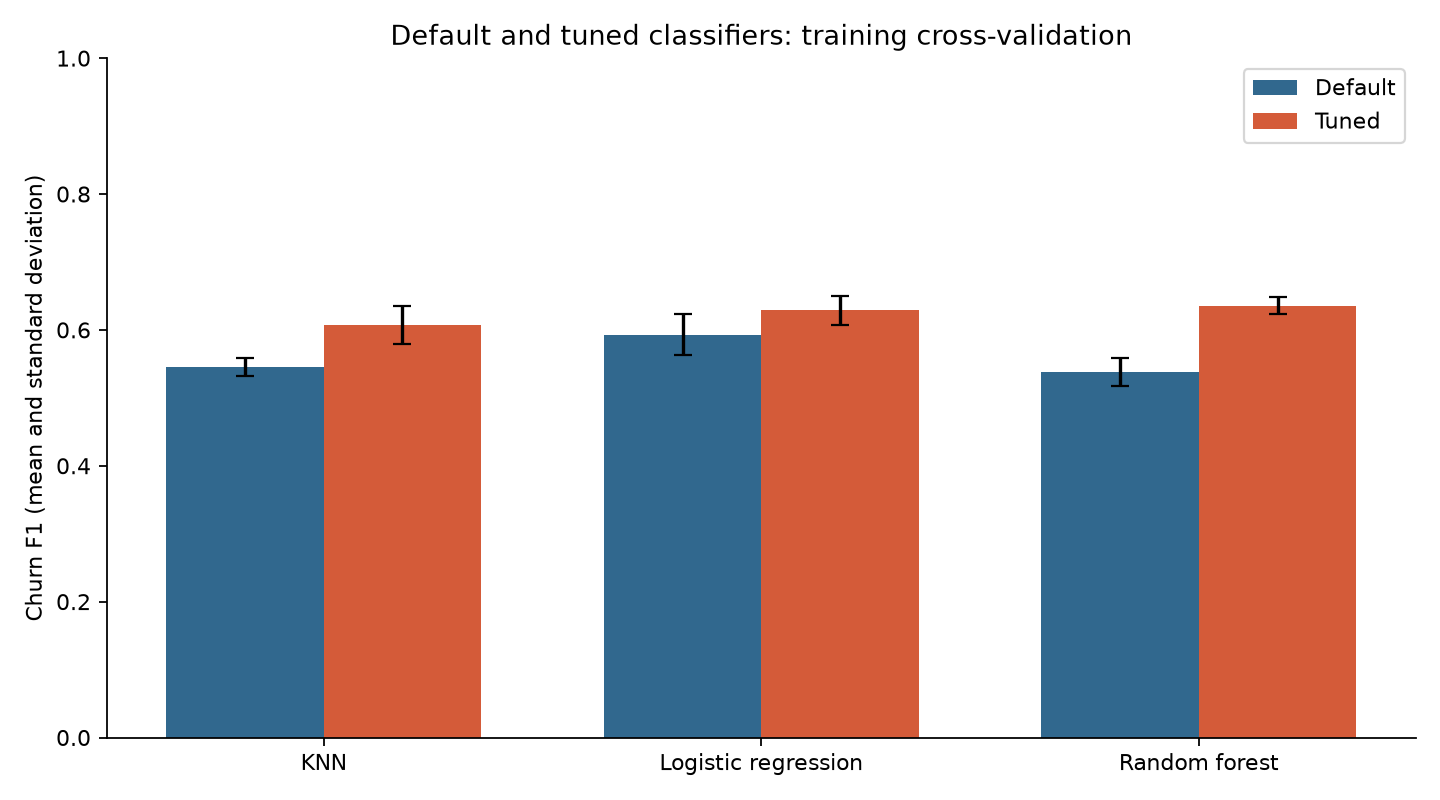

In [3]:
metric_rows = comparison[comparison.metric.isin(SCORING)].copy()
metric_rows["mean +/- std"] = metric_rows.apply(lambda row: f"{row['mean']:.4f} +/- {row['std']:.4f}", axis=1)
display(metric_rows.pivot(index=["model", "setting"], columns="metric", values="mean +/- std")[list(SCORING)])
display(comparison[comparison.metric.isin(["fit_seconds", "score_seconds"])].pivot(index=["model", "setting"], columns="metric", values="mean"))
means = comparison[comparison.metric.eq("f1")].pivot(index="model", columns="setting", values="mean")
stds = comparison[comparison.metric.eq("f1")].pivot(index="model", columns="setting", values="std")
fig, ax = plt.subplots(figsize=(9, 5))
positions = np.arange(len(means))
for offset, setting, color in [(-.18, "default", "#31688e"), (.18, "tuned", "#d45b39")]:
    ax.bar(positions + offset, means[setting], width=.36, yerr=stds[setting], capsize=4, label=setting.capitalize(), color=color)
ax.set_xticks(positions, [{'knn': 'KNN', 'logistic_regression': 'Logistic regression', 'random_forest': 'Random forest'}[name] for name in means.index])
ax.set(title="Default and tuned classifiers: training cross-validation", ylabel="Churn F1 (mean and standard deviation)", ylim=(0, 1))
ax.legend(); ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
figure = ROOT / "outputs" / "figures" / "default_tuned_f1.png"
fig.savefig(figure, dpi=160, metadata={"Software": "Matplotlib"}); plt.close(fig)
display(Image(filename=str(figure)))

## Independent replay of frozen configurations

The saved six configurations are reconstructed and evaluated with the shared evaluator. This is a reproducibility audit, not a new search. It verifies scores, folds, preprocessing statistics and probability ranges without changing the frozen choice or evaluating held-out data. Fitted pipelines and row-level predictions stay in memory.

In [4]:
audit = []
for configuration in frozen["configurations"]:
    name, setting = configuration["model"], configuration["setting"]
    pipeline = build_default_models()[name]
    pipeline["model"].set_params(**configuration["parameters"])
    with warnings.catch_warnings():
        warnings.simplefilter("error", ConvergenceWarning)
        result = evaluate_pipeline(pipeline, X_train, y_train)
    folds, summary = summarise_cv(result)
    expected = comparison[(comparison.model == name) & (comparison.setting == setting)].set_index("metric")
    for metric in SCORING:
        np.testing.assert_allclose(summary.set_index("metric").loc[metric, ["mean", "std"]].to_numpy(dtype=float),
                                   expected.loc[metric, ["mean", "std"]].to_numpy(dtype=float), atol=1e-12, rtol=0)
    for model, (training, validation), used_train, used_val in zip(result["estimator"], fixed_folds().split(X_train, y_train), result["indices"]["train"], result["indices"]["test"]):
        np.testing.assert_array_equal(training, used_train); np.testing.assert_array_equal(validation, used_val)
        fit_data, val_data = X_train.iloc[training], X_train.iloc[validation]
        assert not (set(fit_data.index) | set(val_data.index)) & held_out_indices
        prep = model["preprocess"]
        numeric = prep.named_transformers_["numeric"]
        np.testing.assert_allclose(numeric["impute"].statistics_, fit_data[NUMERIC_COLUMNS].median())
        if "scale" in numeric.named_steps:
            np.testing.assert_allclose(numeric["scale"].mean_, fit_data[NUMERIC_COLUMNS].fillna(fit_data[NUMERIC_COLUMNS].median()).mean())
        for column, vocabulary in zip(CATEGORIES, prep.named_transformers_["categorical"]["encode"].categories_):
            assert set(vocabulary) == set(fit_data[column].dropna())
        probabilities = model.predict_proba(val_data)
        assert np.isfinite(probabilities).all() and ((probabilities >= 0) & (probabilities <= 1)).all()
        np.testing.assert_allclose(probabilities.sum(axis=1), 1)
    audit.append({"configuration": configuration["id"], "folds_verified": 5, "metric_means_and_stds": "matched", "held_out_overlap": 0})
display(pd.DataFrame(audit))

,configuration,folds_verified,metric_means_and_stds,held_out_overlap
0,knn_default,5,matched,0
1,knn_tuned,5,matched,0
2,logistic_regression_default,5,matched,0
3,logistic_regression_tuned,5,matched,0
4,random_forest_default,5,matched,0
5,random_forest_tuned,5,matched,0


## Frozen model choice

Selection considers all six configurations using mean churn F1 before opening final test results. A tuning score can be optimistic because the same validation scores helped choose the parameters. The final held-out evaluation must therefore use these frozen choices without further tuning.

In [5]:
chosen = choose_configuration(comparison)
assert frozen["selected_id"] == f"{chosen['model']}_{chosen['setting']}"
selected = next(c for c in frozen["configurations"] if c["id"] == frozen["selected_id"])
np.testing.assert_allclose(selected["cv_f1"], chosen["mean"])
display(Markdown(f"The frozen choice is **{selected['model'].replace('_', ' ')} ({selected['setting']})**, "
                 f"with mean training CV churn F1 **{selected['cv_f1']:.4f}**. "
                 "It has the highest F1 among the six compared configurations under the declared tie rule. "
                 "This choice used no held-out performance result."))
display(pd.DataFrame([{"parameter": key, "value": str(value)} for key, value in selected["parameters"].items()]))
print("All 40 candidates checked; all six frozen configurations reproduced; held-out data unevaluated.")

The frozen choice is **random forest (tuned)**, with mean training CV churn F1 **0.6354**. It has the highest F1 among the six compared configurations under the declared tie rule. This choice used no held-out performance result.

,parameter,value
0,bootstrap,True
1,ccp_alpha,0.0
2,class_weight,balanced
3,criterion,gini
4,max_depth,None
5,max_features,sqrt
6,max_leaf_nodes,None
7,max_samples,None
8,min_impurity_decrease,0.0
9,min_samples_leaf,5


All 40 candidates checked; all six frozen configurations reproduced; held-out data unevaluated.


## Reproduction and limits

Run `python -m src.train --tune` to reproduce the full 40-candidate search, then run this notebook to replay the six chosen settings and regenerate its figure. Search scores and chosen parameters should reproduce with the pinned software and unchanged data. Wall-clock timings vary. Rerunning an identical freeze is allowed; changing its contents raises an error rather than overwriting it.

Search CSV files, `tuning_configuration.json`, `default_tuned_comparison.csv` and `outputs/frozen_configuration.json` are the durable records. No model binary, customer-level output or held-out metric is exported. The earlier baseline/default tables and figures remain unchanged. Final evaluation, ethics/error analysis and the report remain future work.

## References

scikit-learn developers (n.d.a) *KNeighborsClassifier*. Available at: https://scikit-learn.org/stable/modules/generated/sklearn.neighbors.KNeighborsClassifier.html

scikit-learn developers (n.d.b) *LogisticRegression*. Available at: https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html

scikit-learn developers (n.d.c) *Random forests and other randomized tree ensembles*. Available at: https://scikit-learn.org/stable/modules/ensemble.html#forest

scikit-learn developers (n.d.d) *GridSearchCV*. Available at: https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html

Documentation checked 28 October 2026. Dataset source and placement instructions are in the repository README.